# Analisis Telco Customer Churn (Customer Retention Analytics)

**Dataset:** IBM Sample Telco Customer Churn (dataset publik via Kaggle, 7.043 pelanggan, 21 kolom).
**Pertanyaan bisnis:** pelanggan mana yang berhenti berlangganan (churn), kenapa mereka pergi, dan berapa pendapatan yang hilang?
**Metode:** data dimuat ke SQLite, setiap pertanyaan bisnis dijawab dengan **query SQL asli** (`sql/queries.sql`),
divisualisasikan dalam 12 chart (`charts/`), dan dinarasikan di notebook ini.

**Definisi:** pelanggan churn bila kolom `Churn` bernilai `Yes`. Churn rate = pelanggan churn / total pelanggan pada segmen tersebut.
**Pembersihan penting:** kolom `TotalCharges` tiba sebagai teks dengan 11 nilai kosong tersembunyi (semua tenure 0, Churn No).
Ke-11 baris itu dihapus di `scripts/load_to_sqlite.py` karena pelanggan tersebut belum pernah menerima tagihan —
mengisi nilainya (imputasi) berarti mengarang data. Tabel `customers` berisi **7.032 baris bersih**.

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
from IPython.display import display, Image

# Koneksi ke database hasil load_to_sqlite.py
con = sqlite3.connect("data/telco_churn.db")


def sql(q):
    """Jalankan query SQL dan tampilkan hasilnya sebagai tabel."""
    return pd.read_sql_query(q, con)

## 1. Churn Rate Keseluruhan

Berapa besar tingkat churn di perusahaan secara keseluruhan? Ini menjadi angka pembanding untuk semua segmen berikutnya.

In [2]:
sql("""
SELECT
    COUNT(*)                       AS total_pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers;
""")

,total_pelanggan,churn,rate_persen
0,7032,1869,26.6


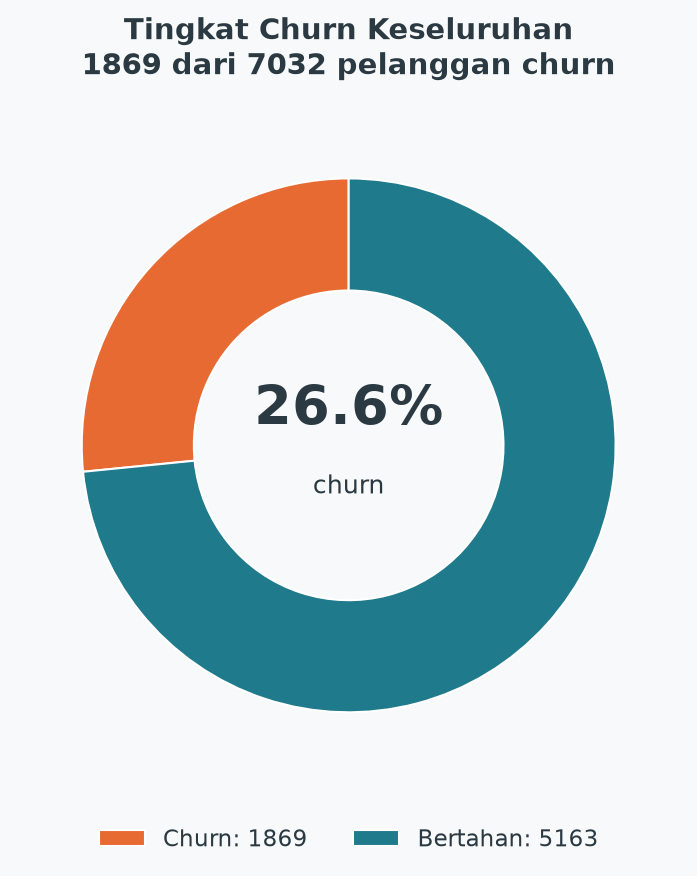

In [3]:
display(Image("charts/01_churn_overall.png"))

**Insight:** dari 7.032 pelanggan, **1.869 berhenti berlangganan** sehingga churn rate keseluruhan adalah **26,6%**.
Lebih dari 1 dari 4 pelanggan pergi. Setiap segmen dengan rate di atas angka ini berarti lebih berisiko dari rata-rata.

## 2. Churn per Jenis Kontrak

Kontrak mana yang paling banyak kehilangan pelanggan?

In [4]:
sql("""
SELECT
    Contract,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY Contract
ORDER BY rate_persen DESC;
""")

,Contract,pelanggan,churn,rate_persen
0,Month-to-month,3875,1655,42.7
1,One year,1472,166,11.3
2,Two year,1685,48,2.8


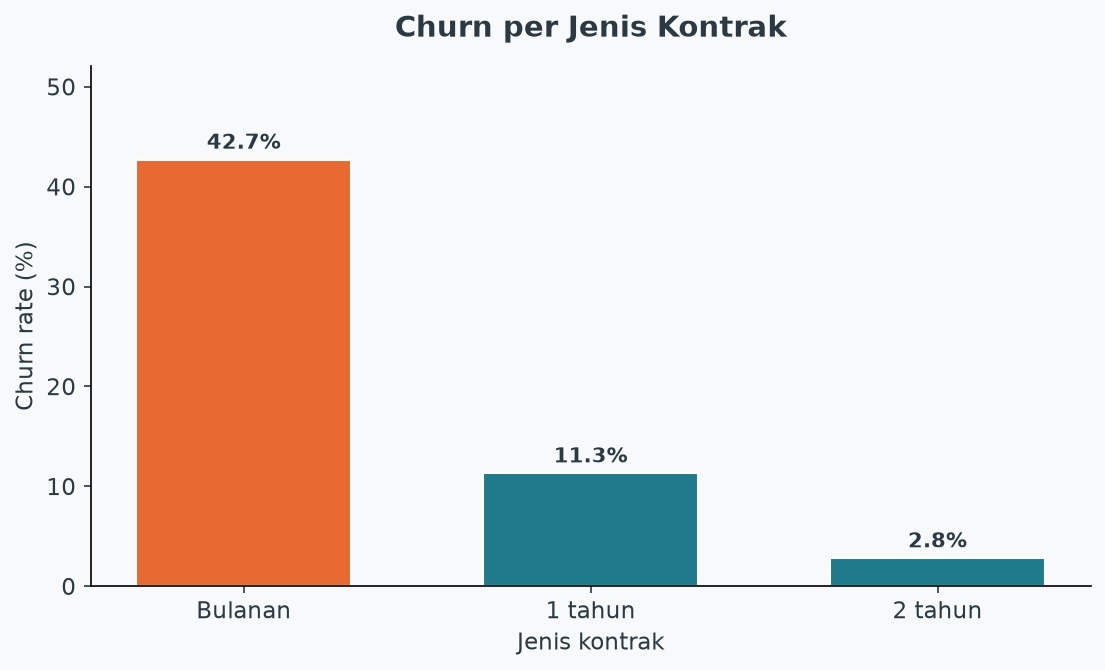

In [5]:
display(Image("charts/02_churn_contract.png"))

**Insight:** kontrak **bulanan (month-to-month) churn 42,7%** (1.655 dari 3.875 pelanggan) —
15 kali lipat kontrak 2 tahun yang hanya 2,8%. Kontrak bulanan mencakup 55,1% pelanggan tetapi menyumbang
**88,6% dari semua churn**. Tanpa komitmen jangka panjang, pelanggan pergi kapan saja.

## 3. Masa Berlangganan (tenure) vs Churn

Tenure dikelompokkan: `0-12`, `13-24`, `25-48`, `49-72` bulan.

In [6]:
sql("""
SELECT
    CASE
        WHEN tenure <= 12  THEN '0-12'
        WHEN tenure <= 24  THEN '13-24'
        WHEN tenure <= 48  THEN '25-48'
        ELSE '49-72'
    END AS band_tenure,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY band_tenure
ORDER BY MIN(tenure);
""")

,band_tenure,pelanggan,churn,rate_persen
0,0-12,2175,1037,47.7
1,13-24,1024,294,28.7
2,25-48,1594,325,20.4
3,49-72,2239,213,9.5


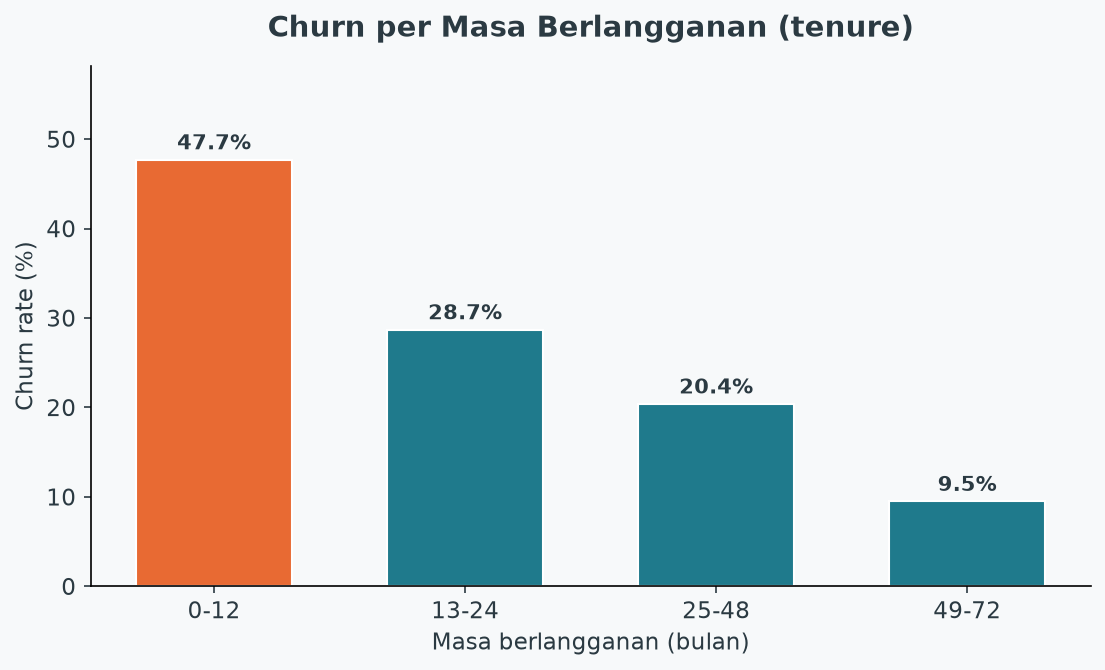

In [7]:
display(Image("charts/03_churn_tenure.png"))

**Insight:** tahun pertama adalah masa paling rawan — pelanggan **0-12 bulan churn 47,7%**
(1.037 dari 2.175), lalu turun bertahap sampai 9,5% setelah 4 tahun. Pelanggan baru menyumbang
**55,5% dari semua churn**. Siapa yang bertahan melewati tahun pertama cenderung setia.

## 4. Layanan Internet vs Churn

DSL, Fiber optic, atau tanpa internet — mana yang paling banyak kehilangan pelanggan?

In [8]:
sql("""
SELECT
    InternetService,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY InternetService
ORDER BY rate_persen DESC;
""")

,InternetService,pelanggan,churn,rate_persen
0,Fiber optic,3096,1297,41.9
1,DSL,2416,459,19.0
2,No,1520,113,7.4


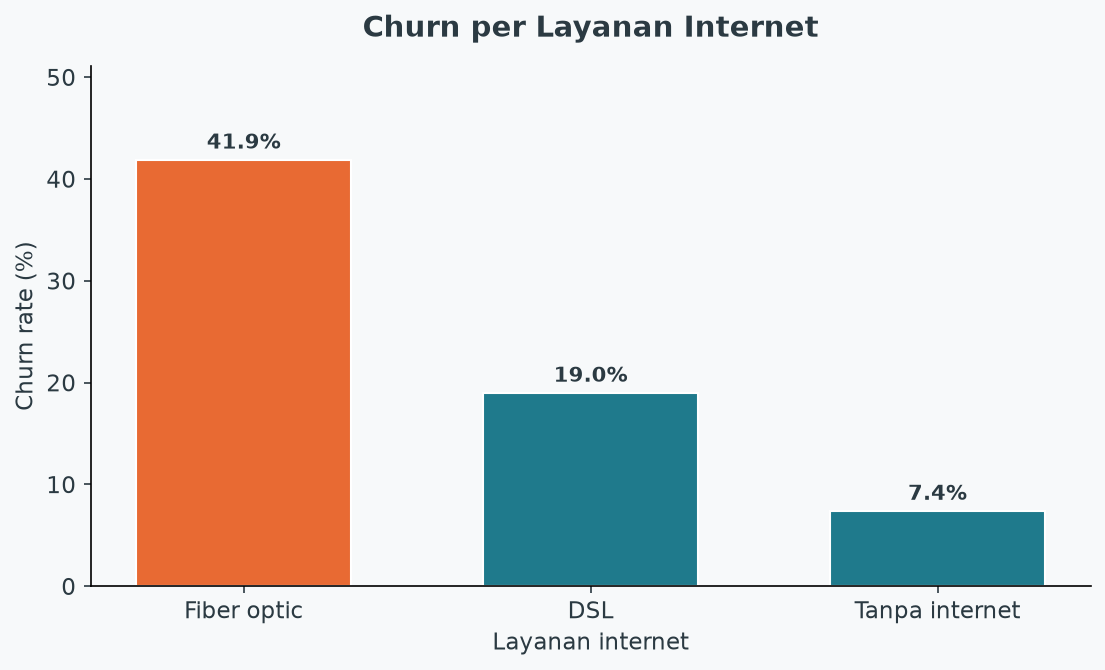

In [9]:
display(Image("charts/04_churn_internet.png"))

**Insight:** pelanggan **Fiber optic churn 41,9%** (1.297 dari 3.096) — lebih dari dua kali DSL (19,0%).
Padahal fiber adalah layanan premium yang paling mahal. Ini sinyal masalah nilai (value): pelanggan membayar
lebih tetapi merasa layanannya tidak sepadan. Pelanggan tanpa internet paling setia (7,4%).

## 5. Metode Pembayaran vs Churn

Metode pembayaran mana yang churnnya paling tinggi?

In [10]:
sql("""
SELECT
    PaymentMethod,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY PaymentMethod
ORDER BY rate_persen DESC;
""")

,PaymentMethod,pelanggan,churn,rate_persen
0,Electronic check,2365,1071,45.3
1,Mailed check,1604,308,19.2
2,Bank transfer (automatic),1542,258,16.7
3,Credit card (automatic),1521,232,15.3


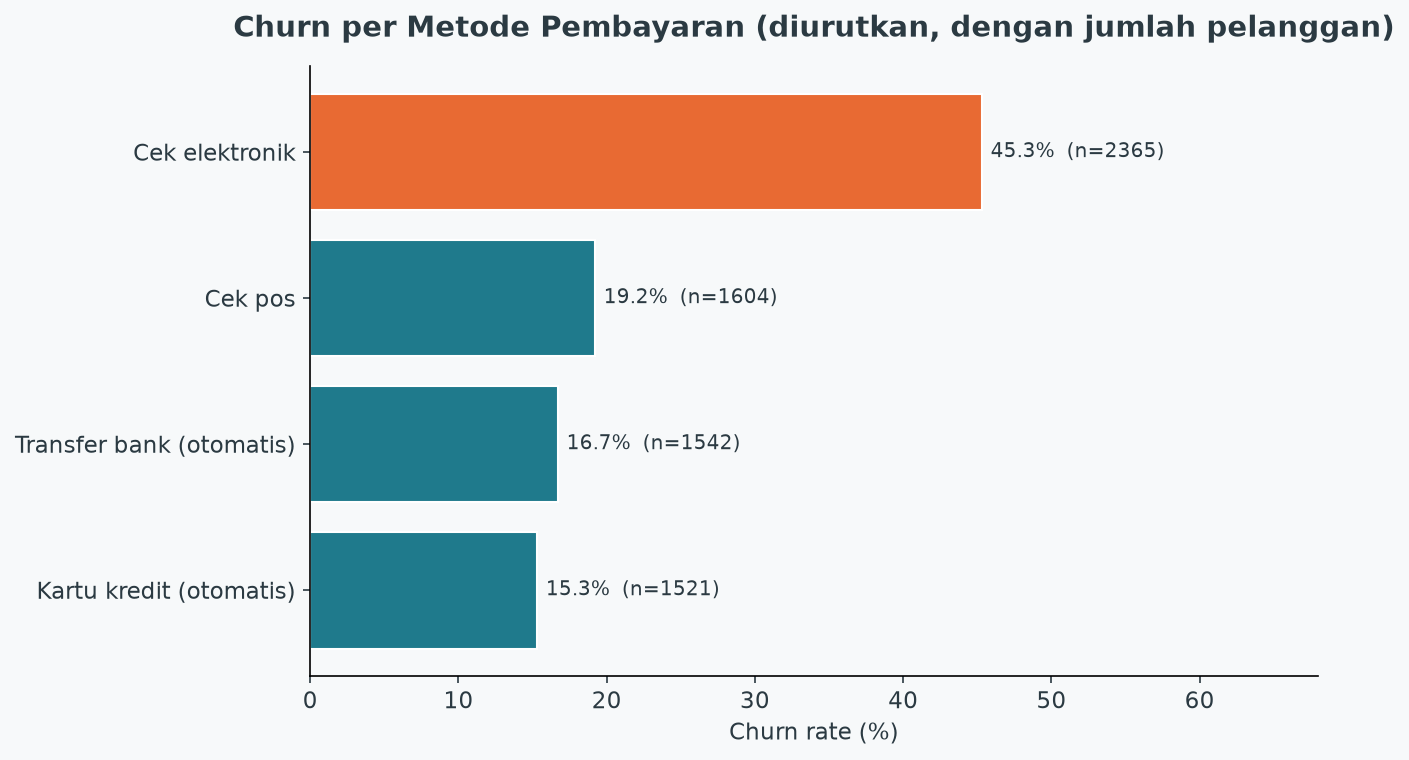

In [11]:
display(Image("charts/05_churn_payment.png"))

**Insight:** pelanggan yang membayar dengan **cek elektronik (electronic check) churn 45,3%**
(1.071 dari 2.365) — hampir 3 kali lipat pelanggan kartu kredit otomatis (15,3%) dan transfer bank otomatis (16,7%).
Pembayaran manual tanpa auto-pay berkorelasi kuat dengan churn: tidak ada pengingat tagihan otomatis,
tidak ada ikatan pembayaran, dan pergi terasa lebih mudah.

## 6. Tagihan Bulanan dan Pendapatan yang Hilang

Tagihan bulanan dikelompokkan: `<= 35`, `36-70`, `71-90`, `> 90` USD. Lalu dihitung berapa pendapatan
bulanan yang hilang akibat churn.

In [12]:
sql("""
SELECT
    CASE
        WHEN MonthlyCharges <= 35  THEN '<= 35'
        WHEN MonthlyCharges <= 70  THEN '36-70'
        WHEN MonthlyCharges <= 90  THEN '71-90'
        ELSE '> 90'
    END AS band_tagihan,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY band_tagihan
ORDER BY MIN(MonthlyCharges);
""")

,band_tagihan,pelanggan,churn,rate_persen
0,<= 35,1729,189,10.9
1,36-70,1722,413,24.0
2,71-90,1842,697,37.8
3,> 90,1739,570,32.8


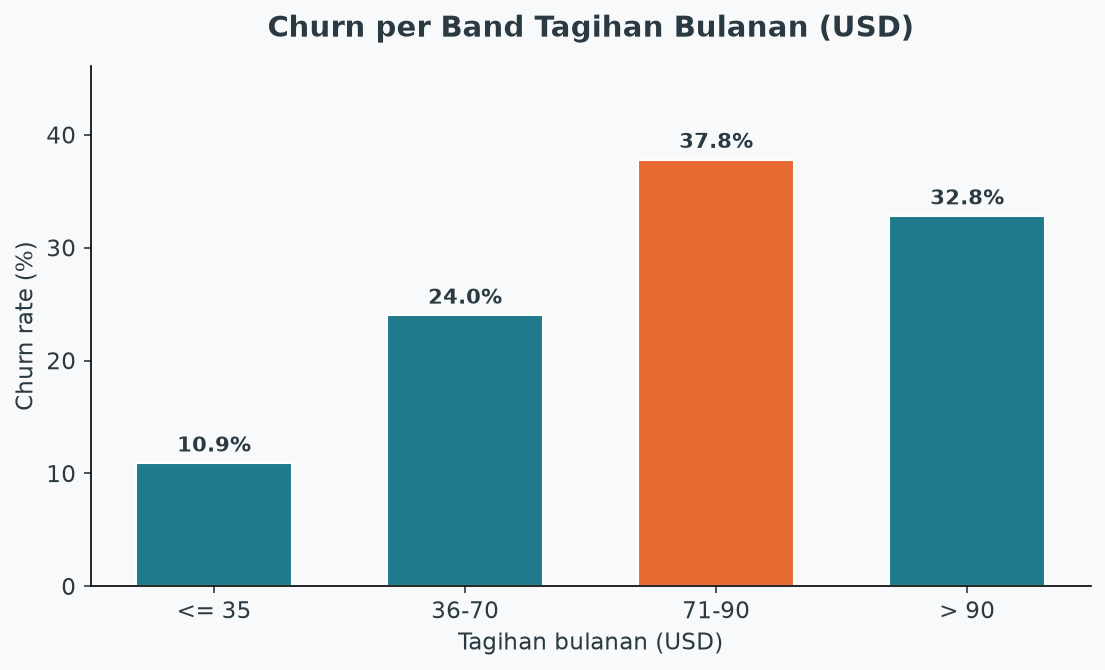

In [13]:
display(Image("charts/06_churn_monthly_charges.png"))

In [14]:
sql("""
SELECT
    SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END) AS pendapatan_hilang_bulanan,
    SUM(MonthlyCharges)                                          AS pendapatan_total_bulanan,
    ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END)
          / SUM(MonthlyCharges), 1)                              AS persen_pendapatan_hilang
FROM customers;
""")

,pendapatan_hilang_bulanan,pendapatan_total_bulanan,persen_pendapatan_hilang
0,139130.85,455661.0,30.5


In [15]:
sql("""
SELECT
    Churn,
    COUNT(*)                       AS pelanggan,
    ROUND(AVG(MonthlyCharges), 2)  AS rata_tagihan_bulanan,
    ROUND(AVG(tenure), 1)          AS rata_tenure_bulan
FROM customers
GROUP BY Churn;
""")

,Churn,pelanggan,rata_tagihan_bulanan,rata_tenure_bulan
0,No,5163,61.31,37.7
1,Yes,1869,74.44,18.0


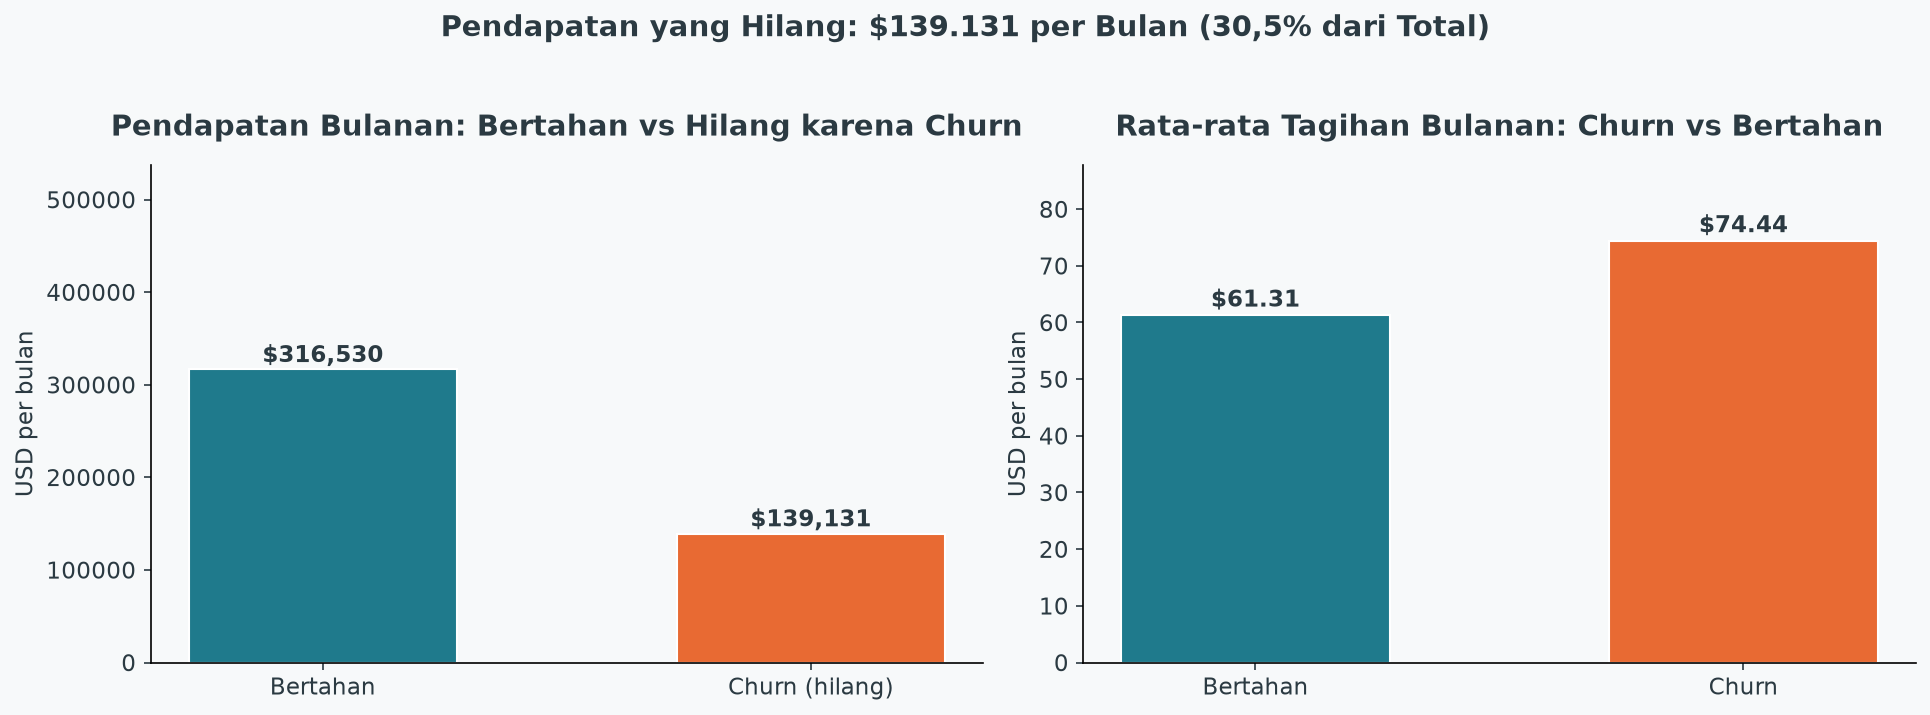

In [16]:
display(Image("charts/09_churn_revenue.png"))

**Insight:** tagihan **71-90 USD churn 37,8%**, tertinggi, sementara tagihan murah (<= 35 USD) hanya 10,9%.
Pelanggan yang churn membayar rata-rata **74,44 USD/bulan** vs 61,31 USD yang bertahan — yang pergi adalah
pelanggan bernilai lebih tinggi. Total **pendapatan yang hilang: 139.131 USD per bulan, atau 30,5%
dari seluruh pendapatan bulanan**. Churn bukan sekadar angka pelanggan, melainkan luka pendapatan.

## 7. Tech Support dan Online Security vs Churn

Apakah layanan dukungan melindungi pelanggan dari churn?

In [17]:
sql("""
SELECT
    TechSupport,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY TechSupport;
""")

,TechSupport,pelanggan,churn,rate_persen
0,No,3472,1446,41.6
1,No internet service,1520,113,7.4
2,Yes,2040,310,15.2


In [18]:
sql("""
SELECT
    OnlineSecurity,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY OnlineSecurity;
""")

,OnlineSecurity,pelanggan,churn,rate_persen
0,No,3497,1461,41.8
1,No internet service,1520,113,7.4
2,Yes,2015,295,14.6


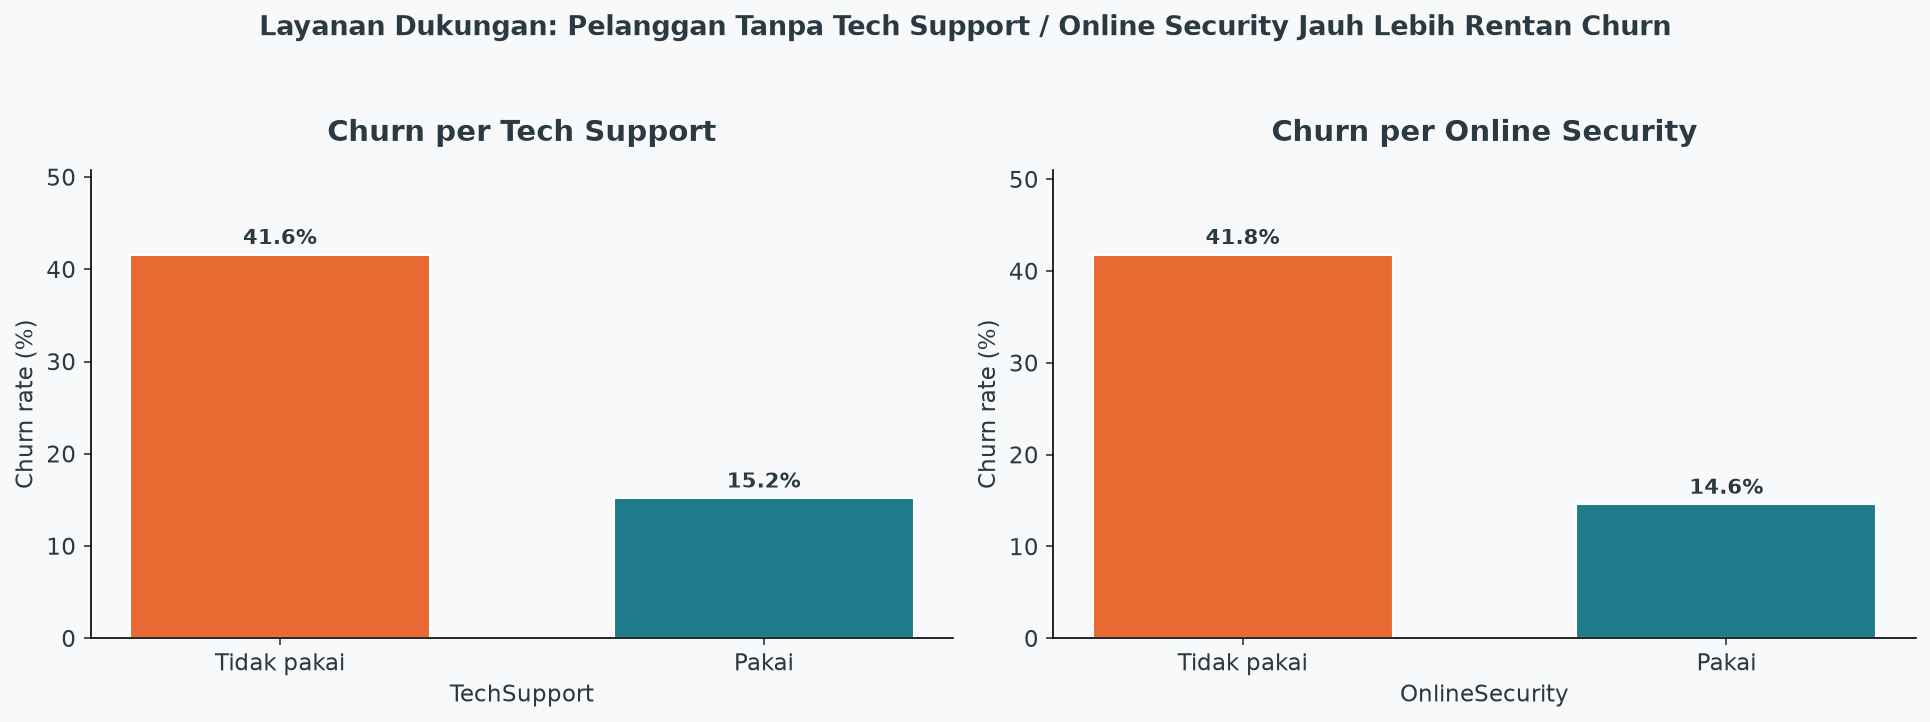

In [19]:
display(Image("charts/07_churn_support.png"))

**Insight:** pelanggan internet **tanpa Tech Support churn 41,6%** vs yang memakai Tech Support hanya 15,2%.
Pola sama pada Online Security: tanpa layanan 41,8% vs memakai 14,6%. Layanan dukungan bukan sekadar fitur —
pelanggan yang merasa dibantu jauh lebih setia. Ini juga menjelaskan sebagian churn fiber: layanan mahal
tanpa dukungan yang dirasakan membuat pelanggan pergi.

## 8. Demografi: Senior, Pasangan, Tanggungan, dan Gender

Apakah profil pelanggan memengaruhi churn?

In [20]:
sql("""
SELECT SeniorCitizen, COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers GROUP BY SeniorCitizen;
""")

,SeniorCitizen,pelanggan,churn,rate_persen
0,0,5890,1393,23.7
1,1,1142,476,41.7


In [21]:
sql("""
SELECT Partner, COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers GROUP BY Partner;
""")

,Partner,pelanggan,churn,rate_persen
0,No,3639,1200,33.0
1,Yes,3393,669,19.7


In [22]:
sql("""
SELECT Dependents, COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers GROUP BY Dependents;
""")

,Dependents,pelanggan,churn,rate_persen
0,No,4933,1543,31.3
1,Yes,2099,326,15.5


In [23]:
sql("""
SELECT gender, COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers GROUP BY gender;
""")

,gender,pelanggan,churn,rate_persen
0,Female,3483,939,27.0
1,Male,3549,930,26.2


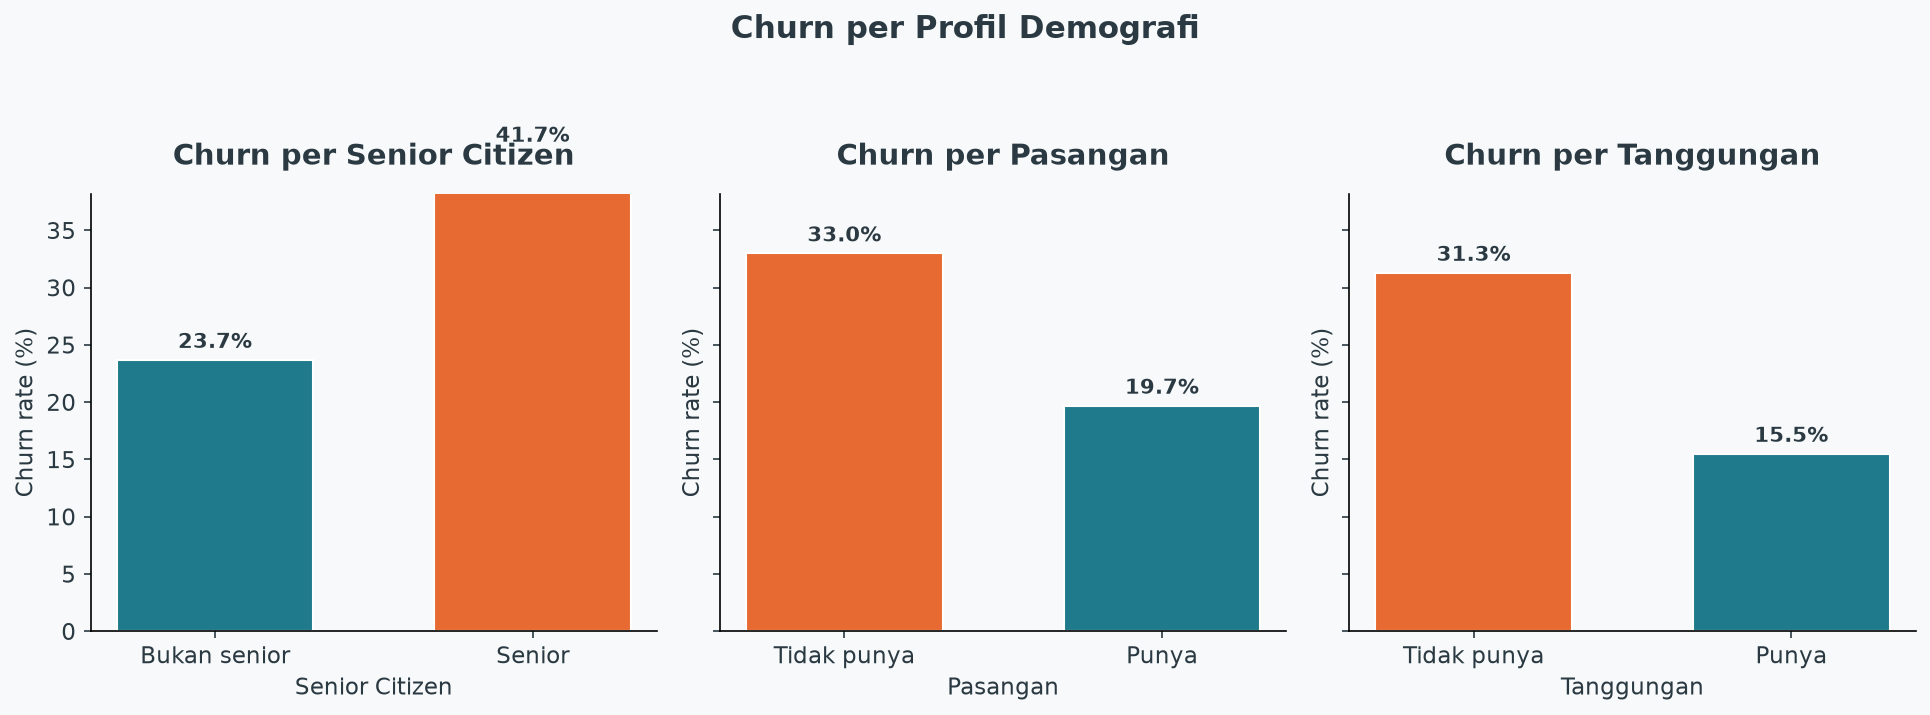

In [24]:
display(Image("charts/08_churn_demografi.png"))

**Insight:** **lansia (senior citizen) churn 41,7%** (476 dari 1.142) vs bukan senior 23,7%.
Pelanggan **tanpa pasangan churn 33,0%** vs punya pasangan 19,7%; **tanpa tanggungan 31,3%** vs
punya tanggungan 15,5%. Polanya konsisten: pelanggan yang hidup sendiri dan tanpa ikatan keluarga
lebih mudah pergi. **Gender hampir tidak berpengaruh** (perempuan 27,0% vs laki-laki 26,2%) —
selisih 0,8 poin, bukan dasar kebijakan.

## 9. Segmen Kombinasi: Di Mana Risiko Menumpuk?

Satu faktor saja sudah berbahaya. Bagaimana bila dua faktor berisiko bertemu pada pelanggan yang sama?

In [25]:
sql("""
-- Kontrak bulanan + pelanggan baru (tenure <= 12)
SELECT COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
WHERE Contract = 'Month-to-month' AND tenure <= 12;
""")

,pelanggan,churn,rate_persen
0,1994,1024,51.4


In [26]:
sql("""
-- Fiber optic + kontrak bulanan
SELECT COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
WHERE InternetService = 'Fiber optic' AND Contract = 'Month-to-month';
""")

,pelanggan,churn,rate_persen
0,2128,1162,54.6


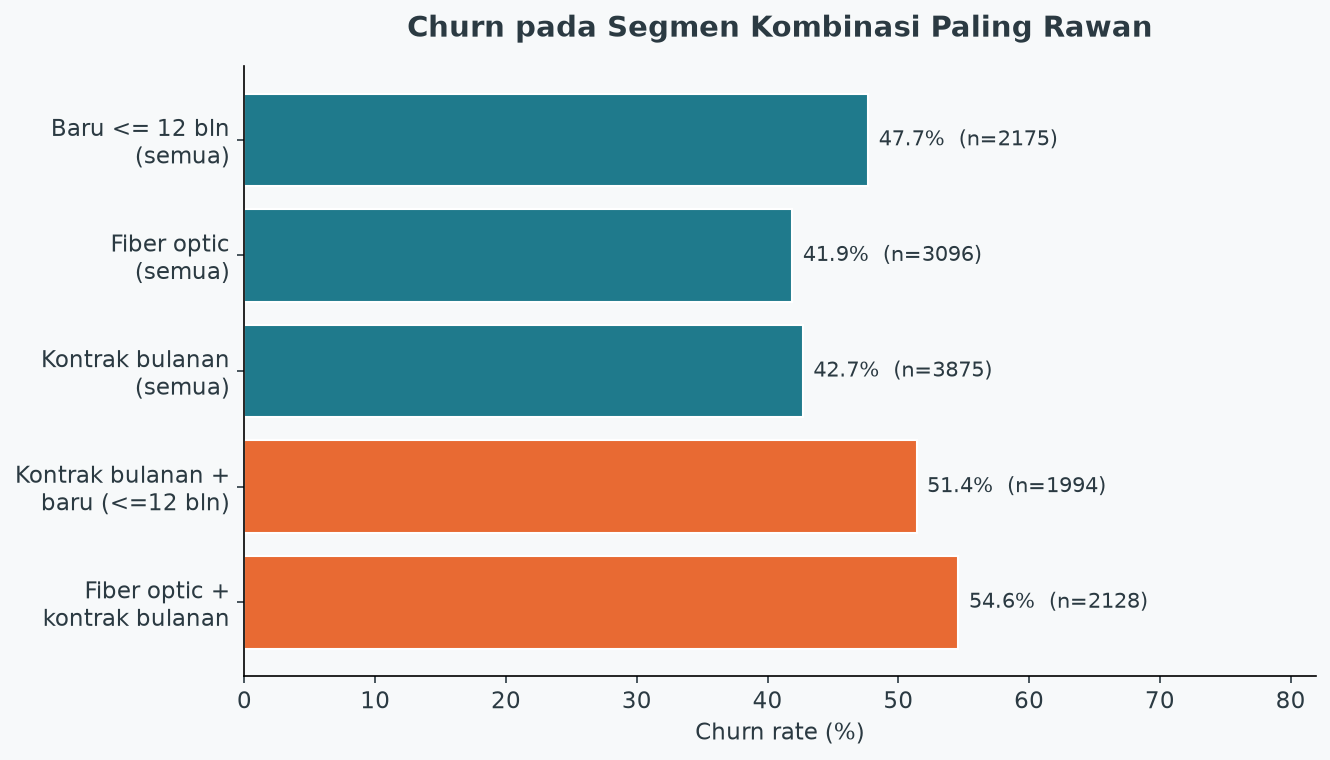

In [27]:
display(Image("charts/10_churn_combo.png"))

**Insight:** kombinasi menumpuk risiko secara dramatis. **Fiber optic + kontrak bulanan: churn 54,6%**
(1.162 dari 2.128) — lebih dari separuh pergi. **Kontrak bulanan + pelanggan baru: 51,4%**
(1.024 dari 1.994). Segmen kombinasi inilah yang harus diprioritaskan: sedikit pelanggan,
dampak terbesar.

## 10. Layanan Tambahan Lain dan Akumulasi Tagihan

Online Backup, Device Protection, Streaming TV, band total tagihan, dan paperless billing.

In [28]:
sql("""
SELECT OnlineBackup, COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers GROUP BY OnlineBackup;
""")

,OnlineBackup,pelanggan,churn,rate_persen
0,No,3087,1233,39.9
1,No internet service,1520,113,7.4
2,Yes,2425,523,21.6


In [29]:
sql("""
SELECT DeviceProtection, COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers GROUP BY DeviceProtection;
""")

,DeviceProtection,pelanggan,churn,rate_persen
0,No,3094,1211,39.1
1,No internet service,1520,113,7.4
2,Yes,2418,545,22.5


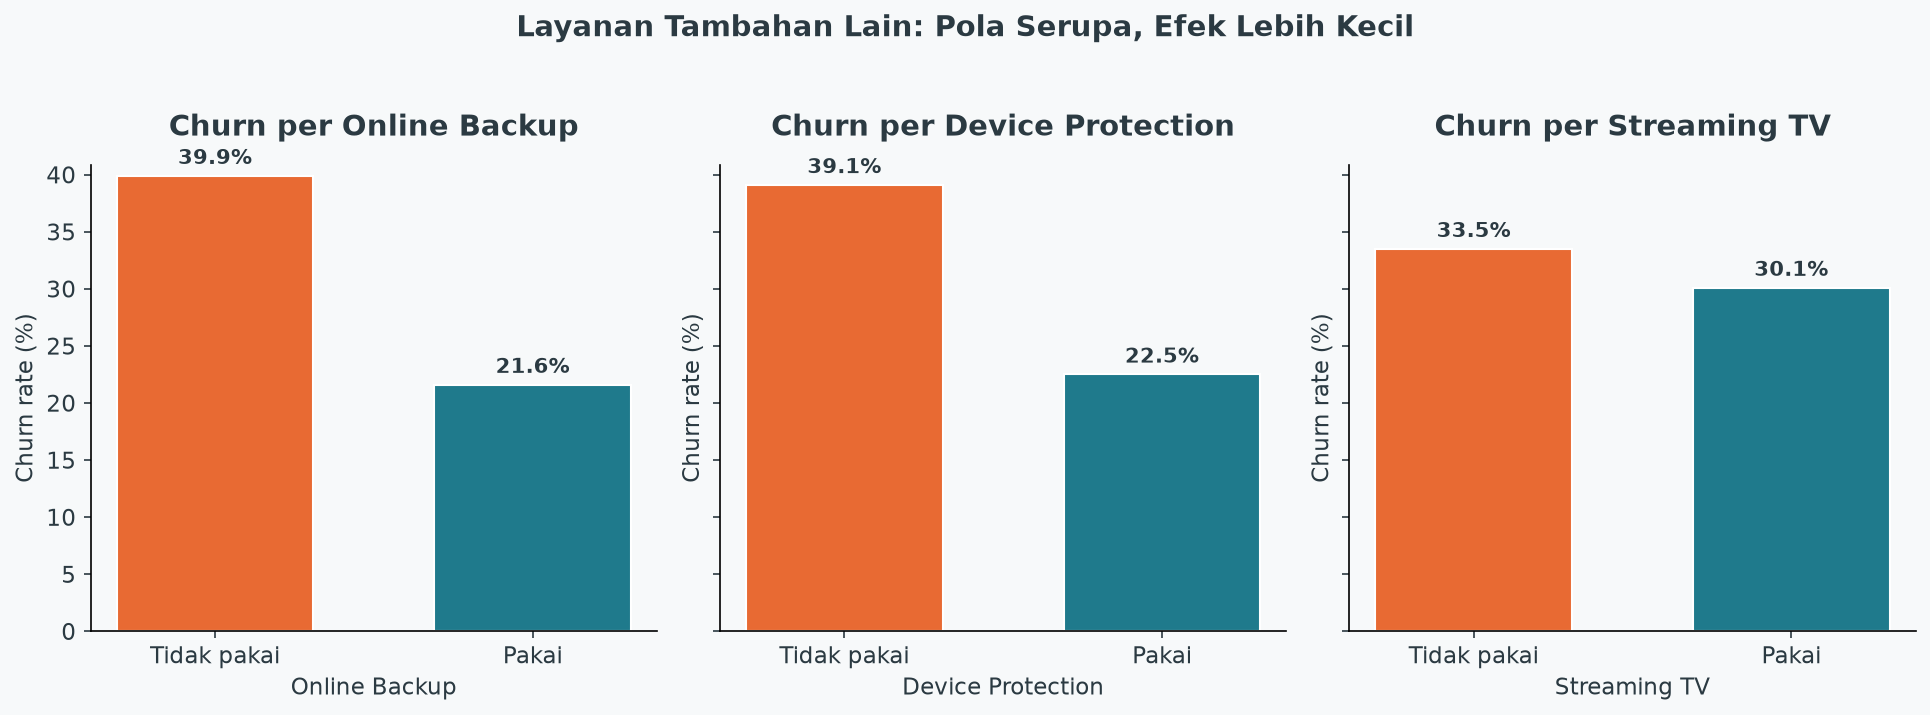

In [30]:
display(Image("charts/11_churn_services.png"))

In [31]:
sql("""
SELECT
    CASE
        WHEN TotalCharges <= 500   THEN '<= 500'
        WHEN TotalCharges <= 2000  THEN '501-2000'
        WHEN TotalCharges <= 5000  THEN '2001-5000'
        ELSE '> 5000'
    END AS band_total_tagihan,
    COUNT(*)                       AS pelanggan,
    SUM(Churn = 'Yes')             AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers
GROUP BY band_total_tagihan
ORDER BY MIN(TotalCharges);
""")

,band_total_tagihan,pelanggan,churn,rate_persen
0,<= 500,2000,829,41.5
1,501-2000,2176,510,23.4
2,2001-5000,1721,373,21.7
3,> 5000,1135,157,13.8


In [32]:
sql("""
SELECT PaperlessBilling, COUNT(*) AS pelanggan, SUM(Churn = 'Yes') AS churn,
    ROUND(100.0 * SUM(Churn = 'Yes') / COUNT(*), 1) AS rate_persen
FROM customers GROUP BY PaperlessBilling;
""")

,PaperlessBilling,pelanggan,churn,rate_persen
0,No,2864,469,16.4
1,Yes,4168,1400,33.6


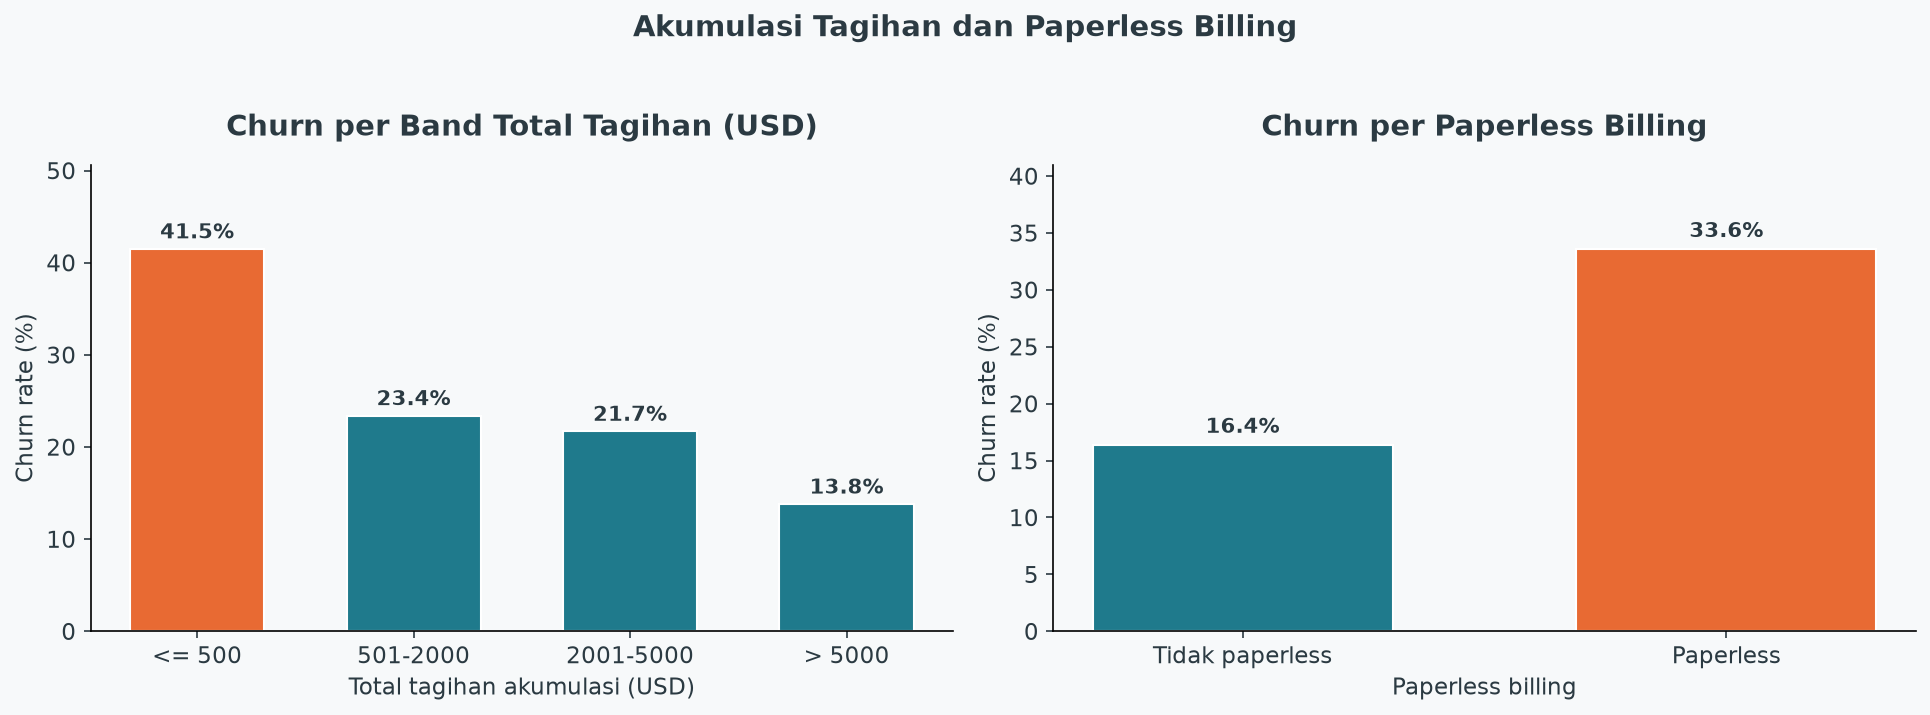

In [33]:
display(Image("charts/12_churn_totalcharges_paperless.png"))

**Insight:** layanan tambahan lain mengikuti pola yang sama tetapi efeknya lebih kecil:
tanpa Online Backup 39,9% vs memakai 21,6%; tanpa Device Protection 39,1% vs memakai 22,5%.
Streaming TV/Movies hampir tidak berpengaruh (sekitar 30-33% di kedua sisi).
Pelanggan dengan **total tagihan akumulasi <= 500 USD churn 41,4%** — mereka yang belum lama berlangganan
dan belum banyak membayar adalah yang paling mudah pergi. **Paperless billing churn 33,6%** vs
tidak paperless 16,4% — tagihan tanpa kertas lebih mudah dilupakan dan dibatalkan.

## 11. Temuan Kunci

| # | Temuan | Angka |
|---|--------|-------|
| 1 | Churn keseluruhan | **26,6%** (1.869 dari 7.032) |
| 2 | Kontrak bulanan | **42,7%**, menyumbang 88,6% semua churn |
| 3 | Pelanggan baru 0-12 bulan | **47,7%**, menyumbang 55,5% semua churn |
| 4 | Fiber optic | **41,9%** vs DSL 19,0% |
| 5 | Cek elektronik | **45,3%** vs kartu kredit otomatis 15,3% |
| 6 | Tanpa Tech Support | **41,6%** vs memakai 15,2% |
| 7 | Tanpa Online Security | **41,8%** vs memakai 14,6% |
| 8 | Senior citizen | **41,7%** vs bukan senior 23,7% |
| 9 | Fiber optic + kontrak bulanan | **54,6%** (segmen kombinasi paling rawan) |
| 10 | Pendapatan hilang | **139.131 USD/bulan** (30,5% pendapatan) |
| 11 | Gender | hampir tidak berpengaruh (27,0% vs 26,2%) |

## 12. Rekomendasi Retensi

1. **Program onboarding 12 bulan pertama yang terstruktur.** Pelanggan baru churn 47,7% —
   sapa proaktif di bulan ke-1, 3, dan 6; tawarkan tur layanan dan cek kepuasan dini.
2. **Konversi kontrak bulanan ke kontrak tahunan dengan insentif.** Kontrak bulanan churn 42,7%
   dan menyumbang 88,6% semua churn — diskon loyalitas, harga terkunci, dan bonus layanan untuk
   yang pindah ke kontrak 1-2 tahun.
3. **Audit nilai layanan Fiber optic.** Churn 41,9% pada layanan termahal adalah alarm:
   tinjau kualitas jaringan per area, harga, dan komunikasi manfaatnya.
4. **Dorong auto-pay dan migrasi dari cek elektronik.** Cek elektronik churn 45,3% —
   insentif kecil untuk pindah ke kartu kredit atau transfer bank otomatis.
5. **Tawarkan Tech Support dan Online Security secara proaktif.** Tanpa dukungan churn 41,6%,
   dengan dukungan 15,2% — bundel dukungan gratis 3 bulan untuk pelanggan baru dan segmen rawan.
6. **Perhatian khusus untuk lansia dan pelanggan yang hidup sendiri.** Senior churn 41,7%,
   tanpa pasangan 33,0% — jalur dukungan yang lebih personal dan mudah dijangkau.

In [34]:
con.close()
print("Analisis selesai.")

Analisis selesai.
